# Customer Purchasing Patterns

This notebook looks at **who** buys and **how** they buy: age, gender, basket size and day of the week.
It builds on the data validation in `retail_sales_analysis.ipynb`, so the data is already known to be clean.

**Questions**
1. Do customers come back, or does each one buy once?
2. Does spending change with age?
3. Do age groups or genders prefer different product categories?
4. How big are baskets, and does basket size drive revenue?
5. Which days of the week sell the most?
6. Are any of these differences real, or just noise?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("retail_sales_dataset.csv", parse_dates=["Date"])

# Fixed colors per category, so a category keeps its color in every chart
CATEGORY_COLORS = {"Electronics": "#2a78d6", "Clothing": "#eb6834", "Beauty": "#1baf7a"}
MAIN_COLOR = "#2a78d6"

# Age groups used throughout (dataset ages run from 18 to 64)
AGE_BINS = [17, 25, 35, 45, 55, 64]
AGE_LABELS = ["18-25", "26-35", "36-45", "46-55", "56-64"]
df["Age Group"] = pd.cut(df["Age"], bins=AGE_BINS, labels=AGE_LABELS)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,26-35
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,26-35
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,46-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,36-45
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,26-35


## 1. Do customers come back?

In [2]:
purchases_per_customer = df.groupby("Customer ID")["Transaction ID"].count()

print("Unique customers:", df["Customer ID"].nunique())
print("Transactions:", len(df))
print("Customers with more than one purchase:", (purchases_per_customer > 1).sum())

Unique customers: 1000
Transactions: 1000
Customers with more than one purchase: 0


Every customer appears exactly once, so there is **no repeat-purchase or loyalty behavior to study**.
"Customer patterns" in this dataset means comparing groups of customers (by age and gender), not following individuals over time.

## 2. Does spending change with age?

,Customers,Revenue,Avg_Spend,Avg_Units
Age Group,,,,
18-25,169,84550,500.3,2.4
26-35,205,98480,480.4,2.6
36-45,202,91870,454.8,2.5
46-55,229,100690,439.7,2.6
56-64,195,80410,412.4,2.4


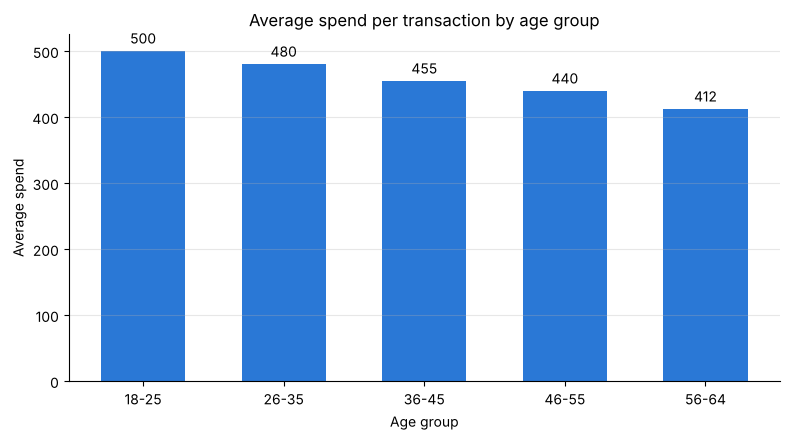

In [3]:
age_summary = df.groupby("Age Group", observed=True).agg(
    Customers=("Customer ID", "count"),
    Revenue=("Total Amount", "sum"),
    Avg_Spend=("Total Amount", "mean"),
    Avg_Units=("Quantity", "mean"),
)
display(age_summary.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(age_summary.index.astype(str), age_summary["Avg_Spend"], color=MAIN_COLOR, width=0.6)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Average spend per transaction by age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Average spend")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Average spend drops slowly with age, from about 500 for 18-25 to about 412 for 56-64.
Section 6 checks whether that gap is big enough to trust.

## 3. Do age groups or genders prefer different categories?

Product Category,Electronics,Clothing,Beauty
Age Group,,,
18-25,31.6,31.4,37.0
26-35,27.7,40.6,31.7
36-45,36.9,32.2,30.9
46-55,35.2,30.3,34.5
56-64,41.6,36.1,22.2


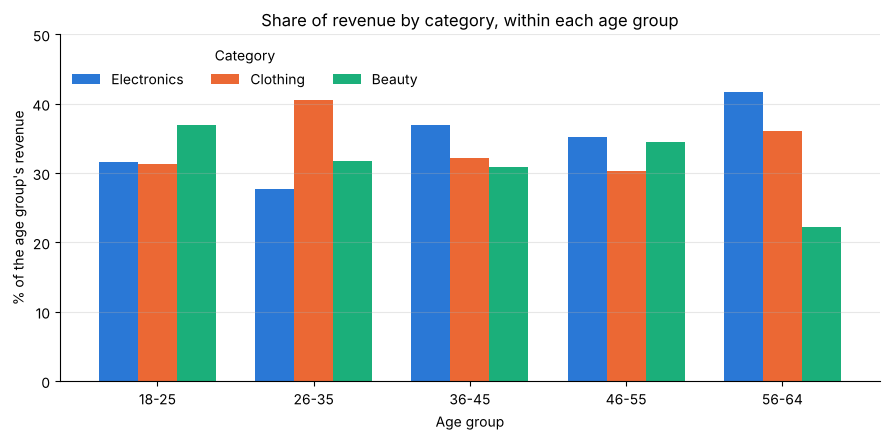

In [4]:
# Share of each age group's revenue that goes to each category (rows add up to 100%)
age_category_share = pd.crosstab(
    df["Age Group"], df["Product Category"],
    values=df["Total Amount"], aggfunc="sum", normalize="index",
)[list(CATEGORY_COLORS)]
display((age_category_share * 100).round(1))

ax = (age_category_share * 100).plot(
    kind="bar", figsize=(9, 4.5), width=0.75,
    color=[CATEGORY_COLORS[c] for c in age_category_share.columns],
)
ax.set_title("Share of revenue by category, within each age group")
ax.set_xlabel("Age group")
ax.set_ylabel("% of the age group's revenue")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, 50)
ax.legend(title="Category", frameon=False, ncol=3, loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
gender_summary = df.groupby("Gender").agg(
    Customers=("Customer ID", "count"),
    Revenue=("Total Amount", "sum"),
    Avg_Spend=("Total Amount", "mean"),
)
display(gender_summary.round(1))

gender_category_share = pd.crosstab(
    df["Gender"], df["Product Category"],
    values=df["Total Amount"], aggfunc="sum", normalize="index",
)[list(CATEGORY_COLORS)]
display((gender_category_share * 100).round(1))

,Customers,Revenue,Avg_Spend
Gender,,,
Female,510,232840,456.5
Male,490,223160,455.4


Product Category,Electronics,Clothing,Beauty
Gender,,,
Female,33.0,34.9,32.1
Male,35.9,33.3,30.8


- The oldest group (56-64) puts about 42% of its spending into Electronics and only 22% into Beauty.
- The youngest group (18-25) leans slightly toward Beauty, and 26-35 toward Clothing.
- Men and women spend almost the same per transaction (about 456 vs 455) and split it across categories almost the same way.

## 4. Basket size

In [6]:
basket = df.groupby("Quantity").agg(
    Transactions=("Transaction ID", "count"),
    Revenue=("Total Amount", "sum"),
    Avg_Spend=("Total Amount", "mean"),
)
basket["Share_of_Revenue_%"] = basket["Revenue"] / basket["Revenue"].sum() * 100
display(basket.round(1))

print("Price points in the data:", sorted(df["Price per Unit"].unique().tolist()))

# Split items into cheap (25-50) and expensive (300-500)
df["Price Tier"] = df["Price per Unit"].map(lambda p: "300-500" if p >= 300 else "25-50")
tiers = df.groupby("Price Tier").agg(Transactions=("Transaction ID", "count"), Revenue=("Total Amount", "sum"))
tiers["Share_of_Sales_%"] = tiers["Transactions"] / tiers["Transactions"].sum() * 100
tiers["Share_of_Revenue_%"] = tiers["Revenue"] / tiers["Revenue"].sum() * 100
display(tiers.round(1))

,Transactions,Revenue,Avg_Spend,Share_of_Revenue_%
Quantity,,,,
1,253,44805,177.1,9.8
2,243,81050,333.5,17.8
3,241,144285,598.7,31.6
4,263,185860,706.7,40.8


Price points in the data: [25, 30, 50, 300, 500]


,Transactions,Revenue,Share_of_Sales_%,Share_of_Revenue_%
Price Tier,,,,
25-50,604,53100,60.4,11.6
300-500,396,402900,39.6,88.4


Baskets of 1, 2, 3 and 4 items are about equally common, but 4-item baskets bring in 41% of revenue versus 10% for single items.
Every product costs one of only five prices (25, 30, 50, 300 or 500). The expensive items (300 or 500) are 40% of sales but **88% of revenue**, so a business would care most about the customers buying those.

## 5. Day of the week

,Transactions,Revenue
Date,,
Monday,146,70250
Tuesday,161,69440
Wednesday,139,58770
Thursday,123,53835
Friday,143,66290
Saturday,150,78815
Sunday,138,58600


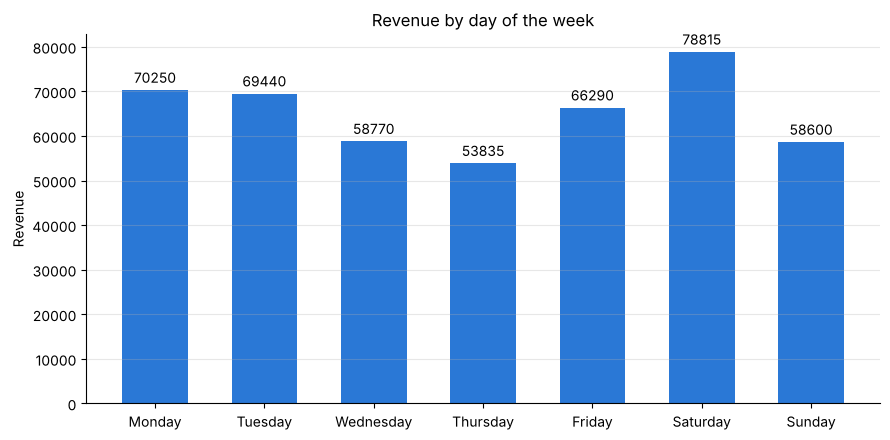

In [7]:
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday = (
    df.groupby(df["Date"].dt.day_name())["Total Amount"]
    .agg(Transactions="count", Revenue="sum")
    .reindex(DAY_ORDER)
)
display(weekday)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(weekday.index, weekday["Revenue"], color=MAIN_COLOR, width=0.6)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Revenue by day of the week")
ax.set_ylabel("Revenue")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Saturday is the strongest day (about 79k) and Thursday the weakest (about 54k).

## 6. Are these differences real?

With only 1,000 sales, some differences will appear just by chance. Three standard tests check that.
A **p-value** below 0.05 is the usual sign that a difference is probably real; above 0.05 means it could easily be random.

In [8]:
# Does spend go down as age goes up? (Spearman correlation)
corr = stats.spearmanr(df["Age"], df["Total Amount"])
print(f"Age vs spend: correlation = {corr.statistic:.3f}, p-value = {corr.pvalue:.3f}")

# Do age groups spend different amounts? (Kruskal-Wallis test)
groups = [g["Total Amount"] for _, g in df.groupby("Age Group", observed=True)]
kw = stats.kruskal(*groups)
print(f"Spend across age groups: p-value = {kw.pvalue:.3f}")

# Do age groups buy different categories? (chi-square test on counts)
counts = pd.crosstab(df["Age Group"], df["Product Category"])
chi2 = stats.chi2_contingency(counts)
print(f"Category mix across age groups: p-value = {chi2.pvalue:.3f}")

# Do men and women buy different categories?
chi2_gender = stats.chi2_contingency(pd.crosstab(df["Gender"], df["Product Category"]))
print(f"Category mix across genders: p-value = {chi2_gender.pvalue:.3f}")

# Do weekdays differ in number of sales? (chi-square goodness of fit)
day_test = stats.chisquare(weekday["Transactions"])
print(f"Transactions across weekdays: p-value = {day_test.pvalue:.3f}")

Age vs spend: correlation = -0.038, p-value = 0.232


Spend across age groups: p-value = 0.436
Category mix across age groups: p-value = 0.637
Category mix across genders: p-value = 0.433
Transactions across weekdays: p-value = 0.451


All p-values are well above 0.05, so **none of the patterns above is strong enough to trust**.
The age, gender, category and weekday differences are about the size you would expect from random variation in 1,000 sales.

## Key findings

1. Each of the 1,000 customers bought exactly once, so there is no loyalty or repeat behavior to analyze.
2. Younger customers spend a little more per transaction and the oldest group leans toward Electronics, but the tests say these gaps could be chance.
3. Men and women behave almost identically.
4. Expensive items (300 or 500) are 40% of sales but 88% of revenue, and bigger baskets bring in much more.
5. The dataset appears to be generated with evenly spread values, so it is good for practicing the workflow but cannot support strong business conclusions.